In [1]:
# Convolutional Neural Network (CNN) - Fashion-MNIST clothing images
# Dataset: Fashion-MNIST, downloaded automatically by Keras on first run
#          (70,000 grayscale 28x28 images of 10 clothing types, ~30 MB, needs internet once)
#
# Needs: pip install tensorflow
#
# Script 34 built a small CNN on 8x8 digits. This one goes further:
#   - bigger, more realistic images
#   - compares a plain Dense network against the CNN on the same data
#   - looks INSIDE the CNN: the filters it learned and the feature maps it produces

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)


C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\syin\AppData\Local\Programs\Python\Python313\Lib\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (60000, 28, 28)  Test: (10000, 28, 28)


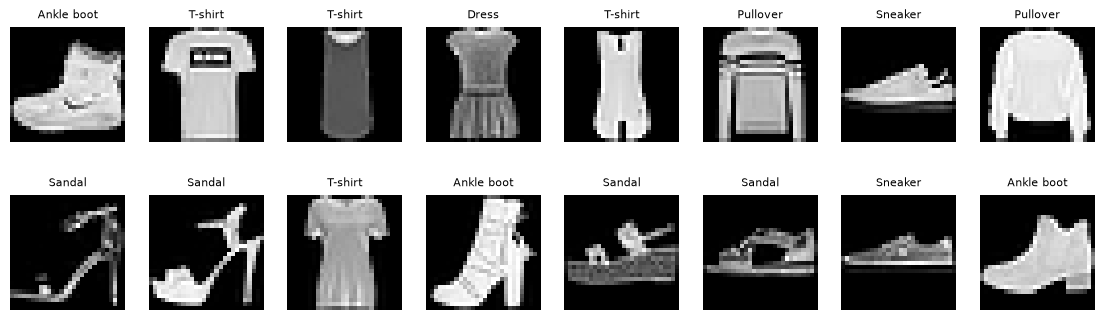

In [2]:
# ---- 1. Load the data ----
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Train:", X_train.shape, " Test:", X_test.shape)

# ---- 2. Look at some images ----
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i], cmap="gray")
    ax.set_title(class_names[y_train[i]], fontsize=8)
    ax.axis("off")
plt.show()

In [3]:
# ---- 3. Preprocess ----
# scale pixels 0-255 -> 0-1, and add the channel dimension CNNs expect
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# ---- 4. Baseline: a plain Dense network (no convolution) ----
dense_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),                       # throws away the 2D structure of the image
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])
dense_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
dense_hist = dense_model.fit(X_train, y_train, validation_split=0.1,
                             epochs=8, batch_size=128, verbose=0)
dense_acc = dense_model.evaluate(X_test, y_test, verbose=0)[1]
print(f"Dense network test accuracy: {dense_acc:.4f}   "
      f"({dense_model.count_params():,} parameters)")

Dense network test accuracy: 0.8730   (109,386 parameters)


In [4]:
# ---- 5. The CNN ----
cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1"),
    layers.MaxPooling2D((2, 2)),            # 28x28 -> 14x14

    layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2"),
    layers.MaxPooling2D((2, 2)),            # 14x14 -> 7x7

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])
cnn.summary()

cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cnn_hist = cnn.fit(X_train, y_train, validation_split=0.1,
                   epochs=8, batch_size=128, verbose=0)

cnn_acc = cnn.evaluate(X_test, y_test, verbose=0)[1]
print(f"\nDense network: {dense_acc:.4f}  ({dense_model.count_params():,} params)")
print(f"CNN          : {cnn_acc:.4f}  ({cnn.count_params():,} params)")
# the CNN usually wins on accuracy - it uses the spatial structure of the image,
# which the Flatten-first Dense network threw away before learning anything


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                       │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                       │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 3136)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │         200,768 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 220,234 (860.29 KB)

 Trainable params: 220,234 (860.29 KB)

 Non-trainable params: 0 (0.00 B)


Dense network: 0.8730  (109,386 params)
CNN          : 0.9080  (220,234 params)


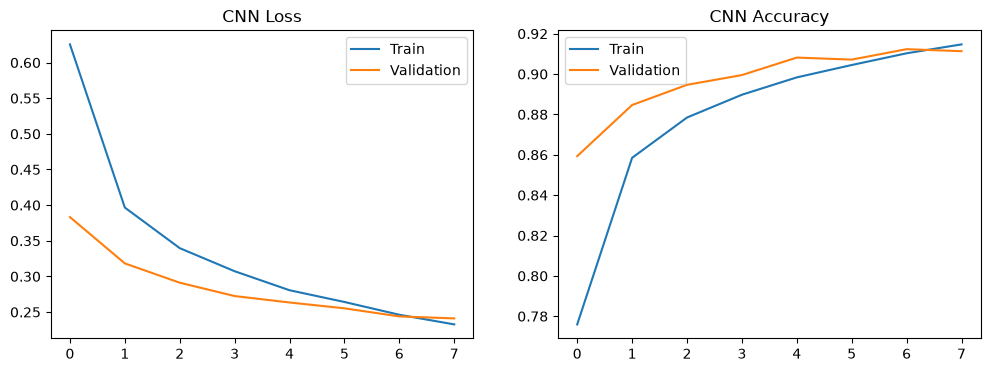

              precision    recall  f1-score   support

     T-shirt       0.87      0.85      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.84      0.87      0.85      1000
       Dress       0.92      0.90      0.91      1000
        Coat       0.79      0.90      0.84      1000
      Sandal       0.97      0.99      0.98      1000
       Shirt       0.78      0.69      0.73      1000
     Sneaker       0.96      0.95      0.96      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



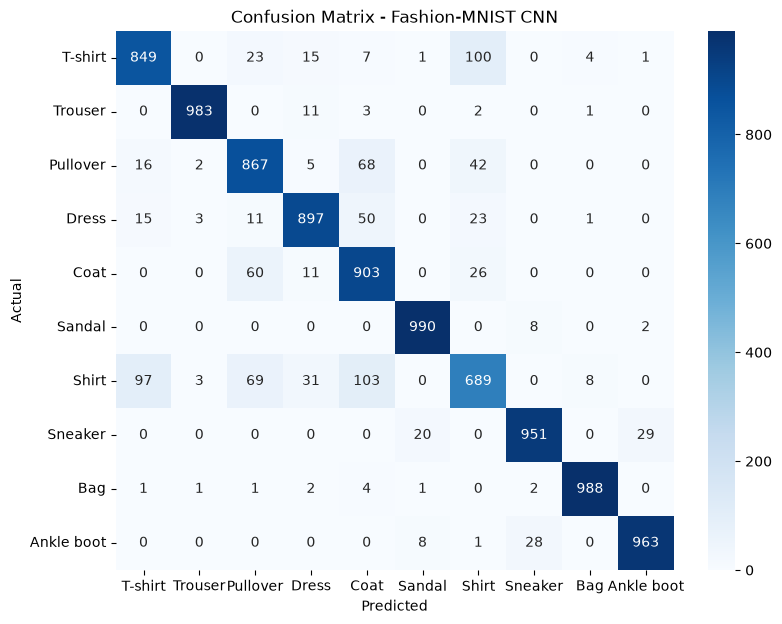

In [5]:
# ---- 6. Training curves ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cnn_hist.history["loss"], label="Train")
axes[0].plot(cnn_hist.history["val_loss"], label="Validation")
axes[0].set_title("CNN Loss")
axes[0].legend()
axes[1].plot(cnn_hist.history["accuracy"], label="Train")
axes[1].plot(cnn_hist.history["val_accuracy"], label="Validation")
axes[1].set_title("CNN Accuracy")
axes[1].legend()
plt.show()

# ---- 7. Evaluate: confusion matrix and per-class report ----
y_pred = np.argmax(cnn.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(9, 7))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix - Fashion-MNIST CNN")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# "Shirt" is usually the hardest class - it gets confused with T-shirt, Pullover and Coat


In [ ]:
# ---- 8. See the filters the CNN LEARNED ----
# in script 43 we hand-wrote kernels like Sobel. Here the network found its own.
filters, biases = cnn.get_layer("conv1").get_weights()
print("conv1 filter weights shape:", filters.shape)    # (3, 3, 1, 32)

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(filters[:, :, 0, i], cmap="gray")
    ax.axis("off")
plt.suptitle("32 filters learned by the first conv layer")
plt.show()

# ---- 9. See the feature maps - what each filter 'sees' in a real image ----
# build a small model that outputs the first conv layer's result
feature_model = keras.Model(inputs=cnn.inputs, outputs=cnn.get_layer("conv1").output)

sample = X_test[:1]
feature_maps = feature_model.predict(sample, verbose=0)    # shape (1, 28, 28, 32)

plt.imshow(sample[0, :, :, 0], cmap="gray")
plt.title(f"Input image: {class_names[y_test[0]]}")
plt.axis("off")
plt.show()

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.axis("off")
plt.suptitle("Feature maps from conv1 - each filter highlights different edges/textures")
plt.show()
